# Estabilidade do riser com choke: lei de válvula, partida do estacionário, paragem adaptativa, espetro e o mapa

O caso de referência da intermitência severa passa a ser um poço: IPR linear na entrada da linha e choke no topo
do riser. A pergunta é onde, num plano abertura do choke × pressão do reservatório, o escoamento é permanente,
cicla com a saída suave ou dá golfada severa, e porquê. Pelo caminho, as alterações ao simulador que o mapa
exigiu, dois erros de análise corrigidos (o passo do integrador e a matriz de massa) e a resposta à pergunta de
partida: o espetro do estado estacionário prevê o mapa.

Issues ilustradas (índice em [docs/issues/INDEX.md](../../docs/issues/INDEX.md)):
- [039](../../docs/issues/039-lei-de-valvula-homogenea.md) lei de válvula homogénea
- [040](../../docs/issues/040-partida-do-estacionario.md) partida a partir do estado estacionário
- [041](../../docs/issues/041-paragem-adaptativa.md) tempo simulado adaptativo
- [042](../../docs/issues/042-modos-locais-da-curva.md) modos locais instáveis na curva
- [043](../../docs/issues/043-mapa-de-intermitencia-severa.md) o mapa
- [047](../../docs/issues/047-passo-maximo-perto-do-equilibrio.md) passo máximo nas corridas que partem de um equilíbrio
- [048](../../docs/issues/048-espetro-com-matriz-de-massa.md) espetro do modelo conservativo com a matriz de massa

*Nenhuma simulação corre aqui. As 252 corridas do mapa vêm de `tools/slug_map.py build` e de
`mfsim batch runs/maps/well/<partida>/batch.json --jobs 12`; `tools/slug_map.py export` grava em
`notebooks/data` o resumo de todas (`severe_slug_map_well.npz`) e cinco corridas completas. O notebook só lê e
desenha. Todas as corridas do mapa usam passo máximo de 1 s (issue 047).*

In [1]:
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

warnings.filterwarnings("ignore")
from mfsim.analysis import cycle_class, jansen_choke_dp_crit, jansen_choke_opening
from mfsim.fluid import Fluid
from mfsim.network.elements import valve_upstream_pressure
from mfsim.plotting import CYCLE_COLORS, CYCLE_LABELS, cycle_map
from mfsim.runs import find_run, load_run

INK, INK2, GRID = "#0b0b0b", "#52514e", "#e1e0d9"
SERIES = {"steady": "#2a78d6", "blocked": "#eb6834"}  # partida do estacionário, partida bloqueada
START_LABEL = {"steady": "partida do estacionário", "blocked": "partida bloqueada"}

with np.load(find_run("severe_slug_map_well")) as z:
    meta = json.loads(str(z["meta"]))
    cols = {k: z[k] for k in z.files if k != "meta"}
rows = [{k: (v[i].item() if hasattr(v[i], "item") else v[i]) for k, v in cols.items()} for i in range(cols["ab"].size)]
for r in rows:
    r["success"] = True
openings = sorted({r["ab"] for r in rows})
pressures = sorted({r["P_res"] for r in rows})
G = {(r["start"], r["P_res"], r["ab"]): r for r in rows}
print(f"{len(rows)} corridas: {len(openings)} aberturas × {len(pressures)} pressões × 2 partidas")
print("caso base:", meta["base_case"], "| paragem:", meta["settle"], "| tf máximo:", meta["tf"], "s")


def run_of(start, ab, P):
    return load_run(find_run(f"severe_slug_map_well_{start}_ab{ab:.3f}_P{P:04.1f}"))


def zones(model):
    """Índices dos nós do esquema: primeiro nó da linha a −3°, célula do ponto baixo (a última da linha),
    início do arco e base do riser."""
    th = np.rad2deg(model.pipes[0].scheme.theta_nodes)
    k_line = int(np.argmax(th < -2.0))
    k_arc = k_line + int(np.argmax(th[k_line:] > -2.0))
    k_base = int(np.argmax(th > 80.0))
    return dict(th=th, k_line=k_line, k_low=k_arc - 1, k_arc=k_arc, k_base=k_base)

252 corridas: 14 aberturas × 9 pressões × 2 partidas
caso base: cases/severe_slug/well_choke.json | paragem: {'window': 2000.0, 't_min': 2000.0, 'amp_tol': 0.1, 'rel_tol': 0.1} | tf máximo: 8000.0 s


## 039 · A lei de válvula decide se o choke estabiliza

A válvula da tese pondera as densidades das fases pela **vazão mássica**; como o gás quase não tem massa, a
densidade da mistura fica perto da do líquido mesmo com o gás a dominar o volume, e o choke quase não resiste ao
gás. A lei homogénea usa a densidade sem escorregamento, ponderada por **volume**, que é o mínimo físico para um
choke bifásico. Em líquido puro as duas coincidem.

 fração mássica de gás  densidade, tese  homogénea  queda homogénea ÷ tese
                 0.002           898 kg/m³     644 kg/m³                     1.4
                 0.010           891 kg/m³     301 kg/m³                     3.0
                 0.030           873 kg/m³     129 kg/m³                     6.9
                 0.100           810 kg/m³      43 kg/m³                    19.1


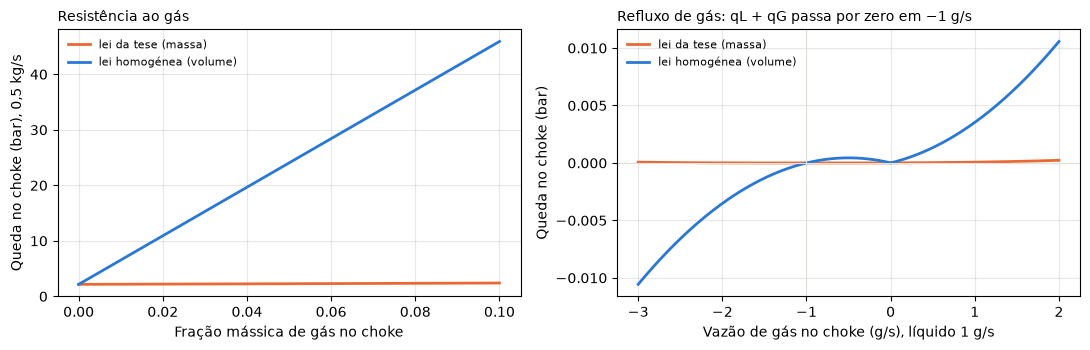

In [2]:
fluid = Fluid(rhoL0=900.0, rhoG0=1.2, muL=2e-3, muG=1.8e-5, gammaL=100.0, gammaG=1.05, P0=1e5, sigma=0.05)
PR, P_DOWN, CV, AB = 1e6, 4e5 / 1e6, 15.0, 0.1


def dp(qL, qG, law):
    return float(valve_upstream_pressure(P_DOWN, qL, qG, AB, CV, fluid, PR, law=law)[1])


rhoL, rhoG = fluid.rhoL0, float(fluid.rhoG(4e5))
print(f"{'fração mássica de gás':>22s} {'densidade, tese':>16s} {'homogénea':>10s} {'queda homogénea ÷ tese':>23s}")
for x in (0.002, 0.01, 0.03, 0.1):
    rt = (1 - x) * rhoL + x * rhoG
    rh = 1 / (x / rhoG + (1 - x) / rhoL)
    print(
        f"{x:22.3f} {rt:13.0f} kg/m³ {rh:7.0f} kg/m³ {dp(0.5 * (1 - x), 0.5 * x, 'homogeneous') / dp(0.5 * (1 - x), 0.5 * x, 'thesis'):23.1f}"
    )

xs = np.linspace(0.0, 0.1, 101)
qG_rev = np.linspace(-3e-3, 2e-3, 501)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))
for law, c, lab in (
    ("thesis", SERIES["blocked"], "lei da tese (massa)"),
    ("homogeneous", SERIES["steady"], "lei homogénea (volume)"),
):
    a1.plot(xs, [dp(0.5 * (1 - x), 0.5 * x, law) for x in xs], color=c, lw=2, label=lab)
    a2.plot(qG_rev * 1e3, [dp(1e-3, g, law) for g in qG_rev], color=c, lw=2, label=lab)
a1.set_xlabel("Fração mássica de gás no choke")
a1.set_ylabel("Queda no choke (bar), 0,5 kg/s")
a1.set_title("Resistência ao gás", loc="left", fontsize=10)
a2.axhline(0, color=GRID, lw=0.8)
a2.axvline(-1.0, color=GRID, lw=0.8)
a2.set_xlabel("Vazão de gás no choke (g/s), líquido 1 g/s")
a2.set_ylabel("Queda no choke (bar)")
a2.set_title("Refluxo de gás: qL + qG passa por zero em −1 g/s", loc="left", fontsize=10)
for a in (a1, a2):
    a.grid(alpha=0.3)
    a.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

No refluxo (à direita) a densidade da tese troca de sinal com a vazão total e a queda fica com o sinal errado:
foi o que fez falhar o integrador em 7 das 126 corridas do primeiro mapa. A lei homogénea não tem divisão pela
vazão total e tem sempre o sinal dela.

## 043 · O mapa

14 aberturas × 9 pressões do reservatório, duas partidas por ponto. **Partida do estacionário**: o estado
estacionário de cada ponto, obtido por continuação de Newton pela grelha e gravado como condição inicial exata,
perturbado em 0,1 % nas pressões. **Partida bloqueada**: linha cheia e riser bloqueado, como depois de uma
paragem. Estável: amplitude da pressão de entrada menor do que 0,1 bar ou 1 % da média, ou sem ciclo até aos
8000 s; golfada severa: pico da vazão de saída de pelo menos 2× a média; ciclo de pressão com saída suave no
resto. Cada célula mostra a pressão de entrada (estável) ou a pressão máxima e o período (com ciclo; média móvel
de 20 s, para as oscilações curtas da coluna do riser não contarem como ciclos). A linha tracejada é o critério
de choke de Jansen, Shoham e Taitel (1996), com a mesma forma (queda constante no choke) mas um limiar mais alto do
que o do próprio modelo (ver o mapa linear, mais abaixo).

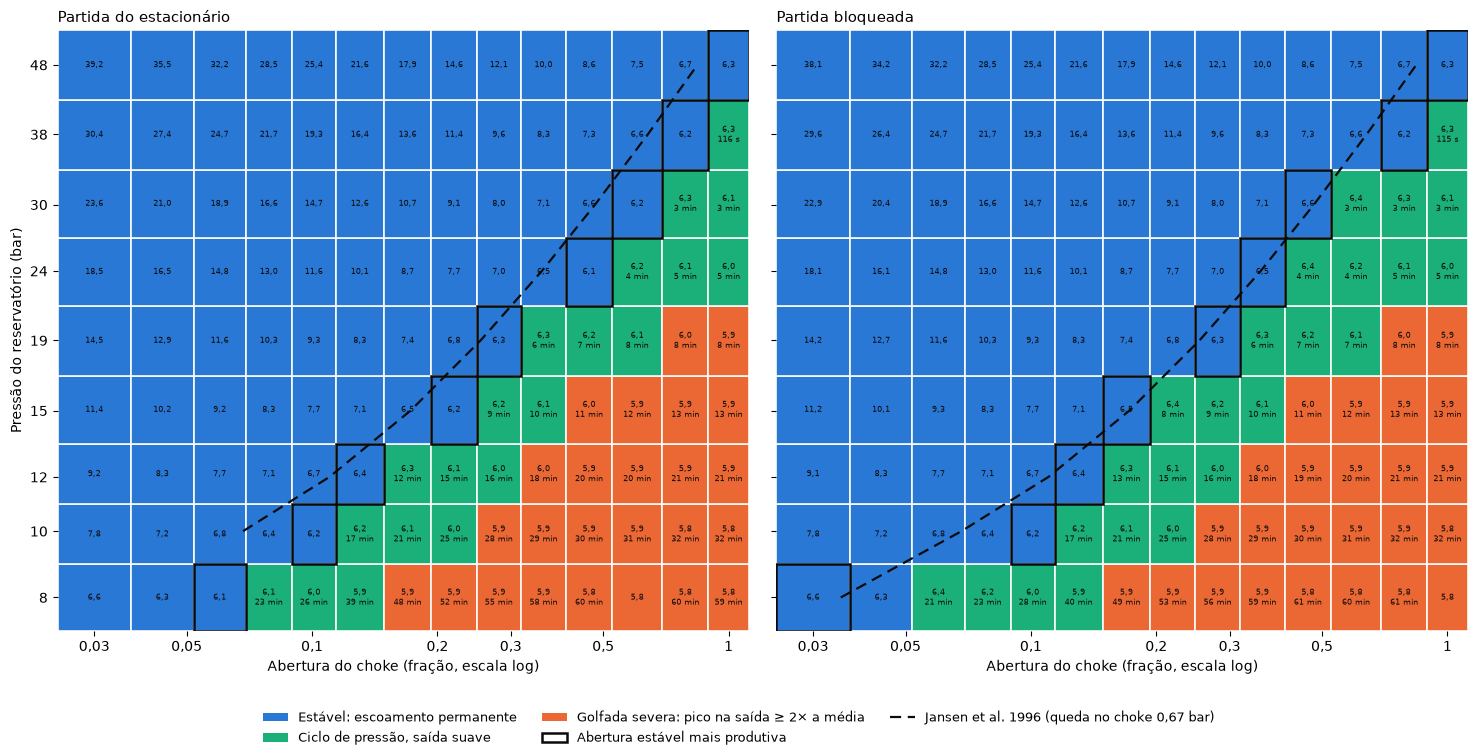

                              estáveis  ciclo  golfada
partida do estacionário             81     20       25
partida bloqueada                   77     24       25
critério de Jansen: queda crítica no choke 0.61–0.72 bar (eqs. 10 e 5)


In [3]:
dpc = 0.5 * (jansen_choke_dp_crit(Phi=0.87) + jansen_choke_dp_crit())
fig, axes = plt.subplots(1, 2, figsize=(15, 7.6), sharey=True)
for ax, start in zip(axes, ("steady", "blocked")):
    sub = [r for r in rows if r["start"] == start]
    xe, ye = cycle_map(ax, sub)
    jx, jy = [], []
    for P in pressures:
        a_c = jansen_choke_opening(
            [r["ab"] for r in sub if r["P_res"] == P], [r["q_mean"] for r in sub if r["P_res"] == P], dpc, CV=15.0
        )
        if a_c is not None:
            jx.append(a_c)
            jy.append(P)
    ax.plot(jx, jy, color=INK, lw=1.6, ls=(0, (5, 3)), zorder=6)
    ticks = [t for t in (0.03, 0.05, 0.1, 0.2, 0.3, 0.5, 1.0) if xe[0] <= t <= xe[-1]]
    ax.set_xticks(ticks)
    ax.set_xticklabels([f"{t:g}".replace(".", ",") for t in ticks])
    ax.set_xlim(xe[0], xe[-1])
    ax.set_xlabel("Abertura do choke (fração, escala log)")
    ax.set_title(START_LABEL[start].capitalize(), loc="left", fontsize=11)
axes[0].set_ylabel("Pressão do reservatório (bar)")
handles = [Patch(fc=CYCLE_COLORS[k], label=CYCLE_LABELS[k]) for k in ("stable", "cycling", "slugging")]
handles += [
    Patch(fc="none", ec=INK, lw=1.8, label="Abertura estável mais produtiva"),
    Line2D(
        [],
        [],
        color=INK,
        lw=1.6,
        ls=(0, (5, 3)),
        label="Jansen et al. 1996 (queda no choke " + f"{dpc:.2f}".replace(".", ",") + " bar)",
    ),
]
fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False, fontsize=9)
fig.subplots_adjust(left=0.05, right=0.99, top=0.95, bottom=0.16, wspace=0.04)
plt.show()

print(f"{'':28s} {'estáveis':>9s} {'ciclo':>6s} {'golfada':>8s}")
for start in ("steady", "blocked"):
    c = [r["cls"] for r in rows if r["start"] == start]
    print(f"{START_LABEL[start]:28s} {c.count('stable'):9d} {c.count('cycling'):6d} {c.count('slugging'):8d}")
print(
    f"critério de Jansen: queda crítica no choke {jansen_choke_dp_crit(Phi=0.87):.2f}–{jansen_choke_dp_crit():.2f} bar (eqs. 10 e 5)"
)

### Histerese

As células em que as duas partidas dão classes diferentes, ao lado da classe linear do estacionário (secção 048).
A partida do estacionário (perturbação de 0,1 %, janelas de 2000 s, amplitude mínima de 0,1 bar) não vê
crescimentos mais lentos do que ~10⁻³ /s, por isso um «estável» dela pode ser uma instabilidade lenta por medir.
**Histerese real** é o estacionário linearmente estável e a partida bloqueada a ciclar: o ciclo-limite coexiste
com o equilíbrio estável (bifurcação subcrítica).

In [4]:
diff = [(P, ab) for P in pressures for ab in openings if G[("steady", P, ab)]["cls"] != G[("blocked", P, ab)]["cls"]]
print(f"{len(diff)} células com classes diferentes entre as partidas")
print(
    f"{'P_res (bar)':>11s} {'abertura':>9s} {'estacionário':>13s} {'bloqueada':>10s} {'linear':>7s} {'λ1 (1/s)':>10s} {'leitura':>34s}"
)
for P, ab in diff:
    s_, b_ = G[("steady", P, ab)], G[("blocked", P, ab)]
    real_h = s_["lin_cls"] == "stable" and b_["cls"] != "stable"
    leitura = (
        "histerese real (subcrítica)"
        if real_h
        else ("instabilidade lenta não medida" if s_["lin_cls"] != "stable" else "--")
    )
    print(
        f"{P:11.0f} {ab:9.3f} {s_['cls']:>13s} {b_['cls']:>10s} {s_['lin_cls']:>7s} {s_['lin_re1']:+10.5f} {leitura:>34s}"
    )
hyst = [
    (P, ab)
    for P in pressures
    for ab in openings
    if G[("steady", P, ab)]["lin_cls"] == "stable" and G[("blocked", P, ab)]["cls"] != "stable"
]
print(
    "histerese real (estacionário linearmente estável, partida bloqueada a ciclar):",
    ", ".join(f"{P:g} bar / {ab:g}" for P, ab in hyst) or "nenhuma",
)

4 células com classes diferentes entre as partidas
P_res (bar)  abertura  estacionário  bloqueada  linear   λ1 (1/s)                            leitura
          8     0.060        stable    cycling  stable   -0.00073        histerese real (subcrítica)
         15     0.220        stable    cycling    hopf   +0.00013     instabilidade lenta não medida
         24     0.460        stable    cycling    hopf   +0.00016     instabilidade lenta não medida
         30     0.600        stable    cycling  stable   -0.00032        histerese real (subcrítica)
histerese real (estacionário linearmente estável, partida bloqueada a ciclar): 8 bar / 0.06, 30 bar / 0.6


## Diagrama de bifurcação a 15 bar e o custo do choke

Para cada abertura: a faixa da pressão de entrada (mínimo e máximo) em cada partida, e o estacionário de partida
(que existe sempre, estável ou não). Em baixo, a produção média simulada e a do estacionário: a diferença entre a
abertura total e a abertura estável mais produtiva é o que um controlador anti-slug que segurasse o estacionário
instável poderia recuperar.

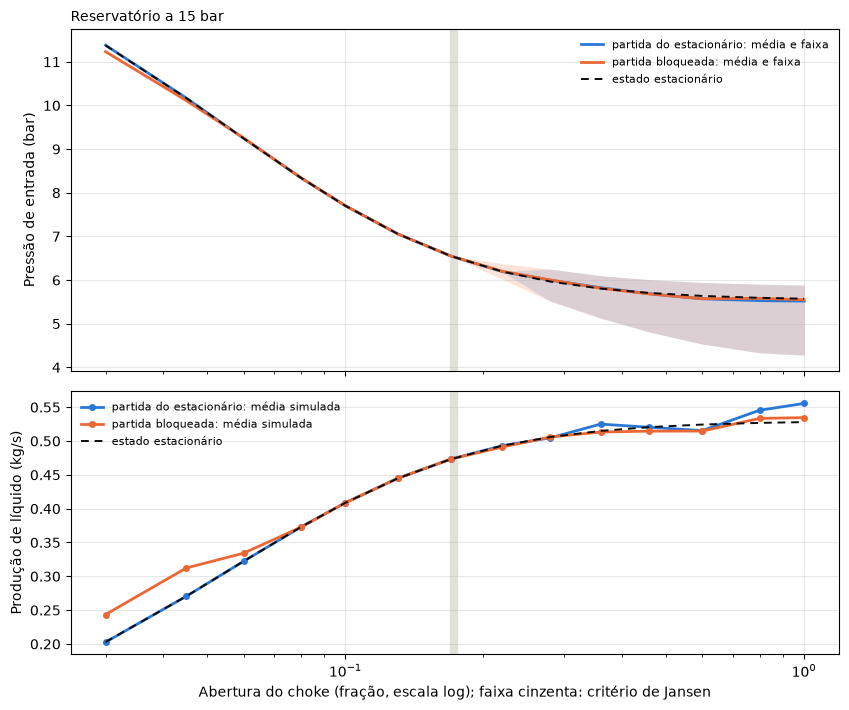

abertura estável mais produtiva: 0.22 -> 0.493 kg/s
abertura total: estacionário 0.528 kg/s, média simulada 0.556 kg/s (slugging)
ganho possível de segurar o estacionário instável: +7.1%


In [5]:
P_SEL = 15.0
fig, (a1, a2) = plt.subplots(2, 1, figsize=(8.5, 7.2), sharex=True, gridspec_kw=dict(height_ratios=[1.3, 1]))
for start in ("steady", "blocked"):
    sub = sorted([G[(start, P_SEL, ab)] for ab in openings], key=lambda r: r["ab"])
    ab = np.array([r["ab"] for r in sub])
    a1.fill_between(ab, [r["P_min"] for r in sub], [r["P_max"] for r in sub], color=SERIES[start], alpha=0.18, lw=0)
    a1.plot(ab, [r["P_mean"] for r in sub], color=SERIES[start], lw=2, label=f"{START_LABEL[start]}: média e faixa")
    a2.plot(
        ab,
        [r["q_mean"] for r in sub],
        color=SERIES[start],
        lw=2,
        marker="o",
        ms=4,
        label=f"{START_LABEL[start]}: média simulada",
    )
st = sorted([G[("steady", P_SEL, ab)] for ab in openings], key=lambda r: r["ab"])
a1.plot([r["ab"] for r in st], [r["P_ss"] for r in st], color=INK, lw=1.4, ls=(0, (4, 3)), label="estado estacionário")
a2.plot([r["ab"] for r in st], [r["q_ss"] for r in st], color=INK, lw=1.4, ls=(0, (4, 3)), label="estado estacionário")
a_c = jansen_choke_opening([r["ab"] for r in st], [r["q_mean"] for r in st], dpc, CV=15.0)
for a in (a1, a2):
    a.axvline(a_c, color=GRID, lw=6, zorder=0)
    a.set_xscale("log")
    a.grid(alpha=0.3)
    a.legend(frameon=False, fontsize=8)
a1.set_ylabel("Pressão de entrada (bar)")
a2.set_ylabel("Produção de líquido (kg/s)")
a2.set_xlabel("Abertura do choke (fração, escala log); faixa cinzenta: critério de Jansen")
a1.set_title(f"Reservatório a {P_SEL:g} bar", loc="left", fontsize=10)
plt.tight_layout()
plt.show()

best = max((r for r in st if r["cls"] == "stable"), key=lambda r: r["q_mean"])
full = G[("steady", P_SEL, 1.0)]
print(f"abertura estável mais produtiva: {best['ab']:.2f} -> {best['q_mean']:.3f} kg/s")
print(f"abertura total: estacionário {full['q_ss']:.3f} kg/s, média simulada {full['q_mean']:.3f} kg/s ({full['cls']})")
print(f"ganho possível de segurar o estacionário instável: {full['q_ss'] / best['q_mean'] - 1:+.1%}")

## Abrir o choke a 15 bar: estável, ciclo de pressão e golfada severa

Três corridas da partida do estacionário, com o choke cada vez mais aberto. Em cima a pressão na entrada da linha,
em baixo a vazão de líquido à saída do riser.

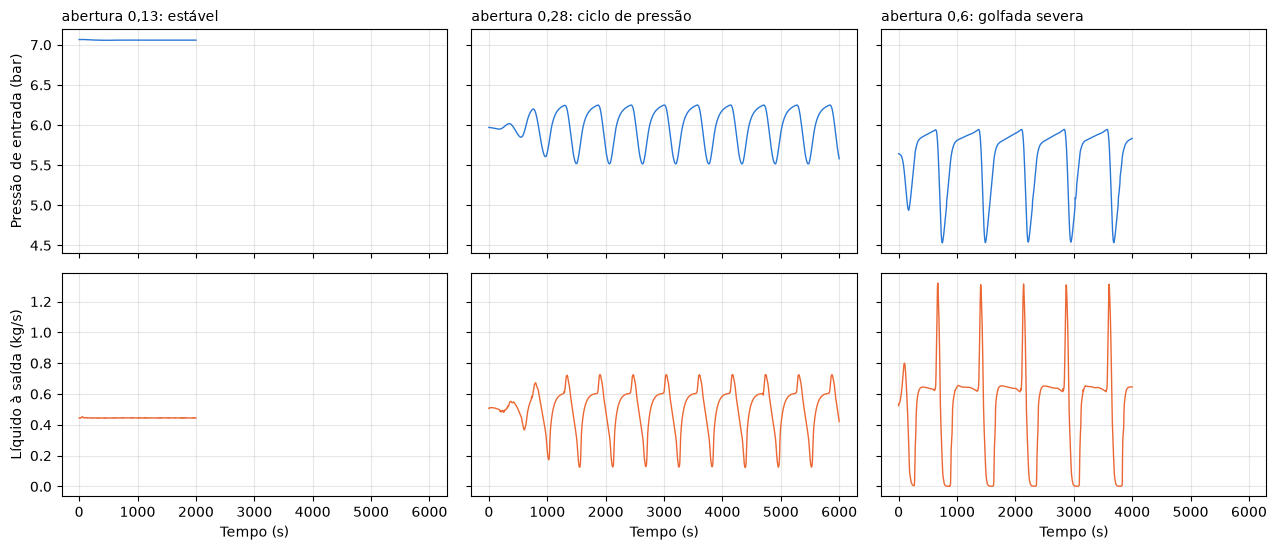

abertura 0.13: stable   P  7.06– 7.07 bar, período      --, saída média 0.445 kg/s, pico  1.0× a média, parou por 'steady' aos 2000
abertura 0.28: cycling  P  5.52– 6.25 bar, período   567 s, saída média 0.505 kg/s, pico  1.4× a média, parou por 'cycle' aos 6000
abertura 0.60: slugging P  4.53– 5.95 bar, período   731 s, saída média 0.515 kg/s, pico  2.5× a média, parou por 'cycle' aos 4000


In [6]:
sel = [(0.13, "estável"), (0.28, "ciclo de pressão"), (0.6, "golfada severa")]
runs = {ab: run_of("steady", ab, P_SEL) for ab, _ in sel}
fig, axes = plt.subplots(2, 3, figsize=(13, 5.6), sharex=True, sharey="row")
for j, (ab, lab) in enumerate(sel):
    r = runs[ab]
    p = r.pipe(0)["out"]
    axes[0, j].plot(r.T, p["P_bar"][1], color=SERIES["steady"], lw=1)
    axes[1, j].plot(r.T, p["qL"][-1], color=SERIES["blocked"], lw=1)
    axes[0, j].set_title(f"abertura {ab:g}: {lab}".replace(".", ","), loc="left", fontsize=10)
    axes[1, j].set_xlabel("Tempo (s)")
    for a in axes[:, j]:
        a.grid(alpha=0.3)
axes[0, 0].set_ylabel("Pressão de entrada (bar)")
axes[1, 0].set_ylabel("Líquido à saída (kg/s)")
plt.tight_layout()
plt.show()
for ab, lab in sel:
    r = G[("steady", P_SEL, ab)]
    per = f"{r['period']:.0f} s" if np.isfinite(r["period"]) else "--"
    print(
        f"abertura {ab:4.2f}: {r['cls']:8s} P {r['P_min']:5.2f}–{r['P_max']:5.2f} bar, período {per:>7s}, saída média {r['q_mean']:.3f} kg/s, pico {r['surge']:4.1f}× a média, parou por '{r['settle']}' aos {r['t_end']:.0f}"
    )

### A golfada no espaço e no tempo

Fração de gás nos últimos 80 m da linha, no arco e no riser, contra o tempo. No ciclo de pressão o riser
respira sem se encher de líquido; na golfada severa o líquido acumula-se no ponto baixo e sobe o riser até o
bloquear, a linha pressuriza e o gás expulsa o tampão (as faixas claras que atravessam o riser).

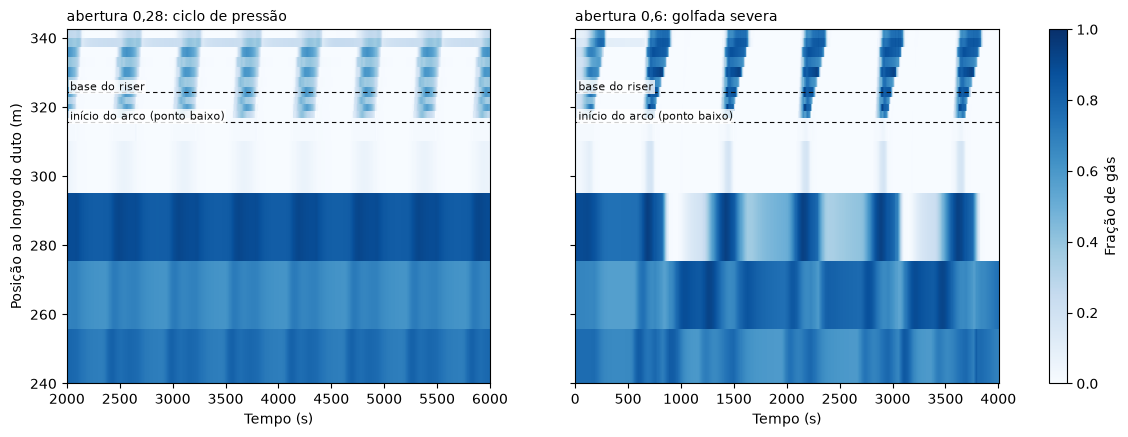

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
for ax, ab in zip(axes, (0.28, 0.6)):
    r = runs[ab]
    p = r.pipe(0)
    x = np.asarray(p["x"])
    t_win = r.T >= r.T[-1] - 4000
    im = ax.pcolormesh(
        r.T[t_win], x, p["out"]["alphaG"][:, t_win], cmap="Blues", vmin=0, vmax=1, shading="auto", rasterized=True
    )
    z = zones(r.model)
    for xv, lab in ((x[z["k_arc"]], "início do arco (ponto baixo)"), (x[z["k_base"]], "base do riser")):
        ax.axhline(xv, color=INK, lw=0.8, ls=(0, (4, 3)))
        ax.text(
            r.T[t_win][0] + 30, xv + 0.6, lab, fontsize=8, color=INK, bbox=dict(fc="white", ec="none", alpha=0.8, pad=1)
        )
    ax.set_ylim(240, x[-1])
    ax.set_xlabel("Tempo (s)")
    ax.set_title(f"abertura {ab:g}: {dict(sel)[ab]}".replace(".", ","), loc="left", fontsize=10)
axes[0].set_ylabel("Posição ao longo do duto (m)")
fig.colorbar(im, ax=axes, label="Fração de gás", fraction=0.025)
plt.show()

### A célula de histerese real a 8 bar e abertura 0,06

O estacionário é linearmente estável (o par lento é amortecido); a partida do estacionário fica nele, a partida
bloqueada instala um ciclo de pressão que não desaparece.

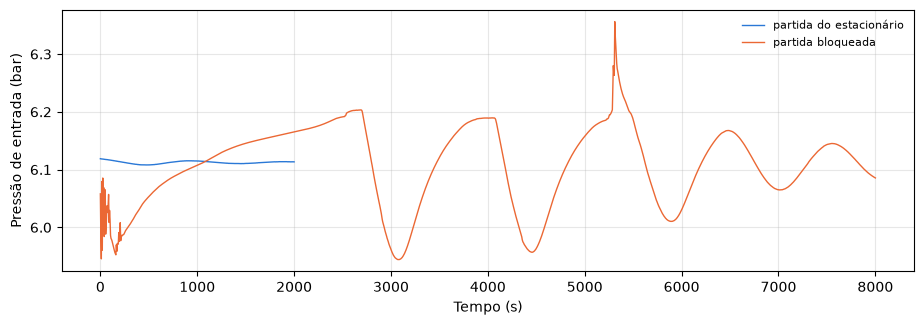

classe linear do estacionário: stable, λ1 = -0.00073+0.00693j /s
partida do estacionário : stable   amplitude 0.011 bar, período --, parou por 'steady' aos 2000
partida bloqueada       : cycling  amplitude 0.137 bar, período 1279 s, parou por 'tf' aos 8000


In [8]:
H_P, H_AB = 8.0, 0.06
fig, ax = plt.subplots(figsize=(11, 3.4))
for start in ("steady", "blocked"):
    r = run_of(start, H_AB, H_P)
    ax.plot(r.T, r.pipe(0)["out"]["P_bar"][1], color=SERIES[start], lw=1, label=START_LABEL[start])
ax.set_xlabel("Tempo (s)")
ax.set_ylabel("Pressão de entrada (bar)")
ax.grid(alpha=0.3)
ax.legend(frameon=False, fontsize=8)
plt.show()
lin = G[("steady", H_P, H_AB)]
print(f"classe linear do estacionário: {lin['lin_cls']}, λ1 = {lin['lin_re1']:+.5f}{lin['lin_im1']:+.5f}j /s")
for start in ("steady", "blocked"):
    r = G[(start, H_P, H_AB)]
    per = f"{r['period']:.0f} s" if np.isfinite(r["period"]) else "--"
    print(
        f"{START_LABEL[start]:24s}: {r['cls']:8s} amplitude {r['amp']:.3f} bar, período {per}, parou por '{r['settle']}' aos {r['t_end']:.0f}"
    )

## 040 e 041 · Partida do estacionário e paragem adaptativa

Todas as partidas do estacionário convergiram no Newton (o estado gravado já era o estacionário). A paragem
adaptativa integra em janelas de 2000 s e para quando a amplitude fica abaixo da tolerância ou o ciclo se repete;
uma deriva sem ciclo segue até aos 8000 s e conta como estável. A paragem adaptativa poupa tempo, mas **não é um
teste de estabilidade**: a partir de uma perturbação de 0,1 %, uma instabilidade que cresce a 10⁻³ /s ainda não
passa de 0,1 bar quando a primeira janela acaba.

Newton convergiu na partida do estacionário: 126 de 126
                          permanente  ciclo repetido  tempo máximo  passos (mediana)
partida do estacionário           77              26            23              8094
partida bloqueada                 75              26            25             11686


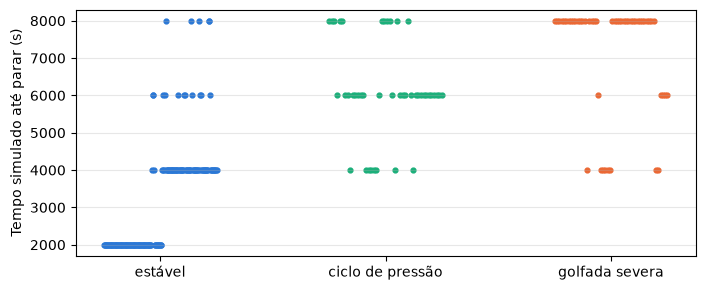

In [9]:
print(
    f"Newton convergiu na partida do estacionário: {sum(r['initial'] for r in rows if r['start'] == 'steady')} de {len(openings) * len(pressures)}"
)
print(f"{'':24s} {'permanente':>11s} {'ciclo repetido':>15s} {'tempo máximo':>13s} {'passos (mediana)':>17s}")
for start in ("steady", "blocked"):
    sub = [r for r in rows if r["start"] == start]
    s = [r["settle"] for r in sub]
    print(
        f"{START_LABEL[start]:24s} {s.count('steady'):11d} {s.count('cycle'):15d} {s.count('tf'):13d} {int(np.median([r['n_steps'] for r in sub])):17d}"
    )
fig, ax = plt.subplots(figsize=(8, 3.2))
for k, cls in enumerate(("stable", "cycling", "slugging")):
    t = [r["t_end"] for r in rows if r["cls"] == cls]
    ax.scatter(np.full(len(t), k) + np.linspace(-0.25, 0.25, len(t)), t, s=12, color=CYCLE_COLORS[cls])
ax.set_xticks([0, 1, 2])
ax.set_xticklabels(["estável", "ciclo de pressão", "golfada severa"])
ax.set_ylabel("Tempo simulado até parar (s)")
ax.grid(alpha=0.3, axis="y")
plt.show()

## 048 · O espetro do estacionário prevê o mapa

No modo conservativo o lado direito do modelo devolve a derivada das massas por volume das células, não a dos
estados: a linearização é M·δẋ = J·δx, com M = ∂T/∂x (`mfsim.analysis.mass_matrix`), e os autovalores certos
são os do problema generalizado (`linear_spectrum`). Uma primeira versão desta análise usou os de J sozinha e
concluiu que os autovalores não desenhavam o mapa; estava errada (issue 048, nota no topo da 042).

Os modos separam-se pelo número efetivo de nós do vetor próprio (`mode_participation`): **globais** (pelo
menos 4 nós) e **locais** (presos a uma ou duas células). A classe linear do estacionário vem do modo global
lento dominante (`slow_global_modes`): amortecido (estável), par complexo instável (bifurcação de Hopf: ciclo
de pressão) ou real instável (instabilidade monotónica: golfada de relaxação).

### Três pontos a 15 bar

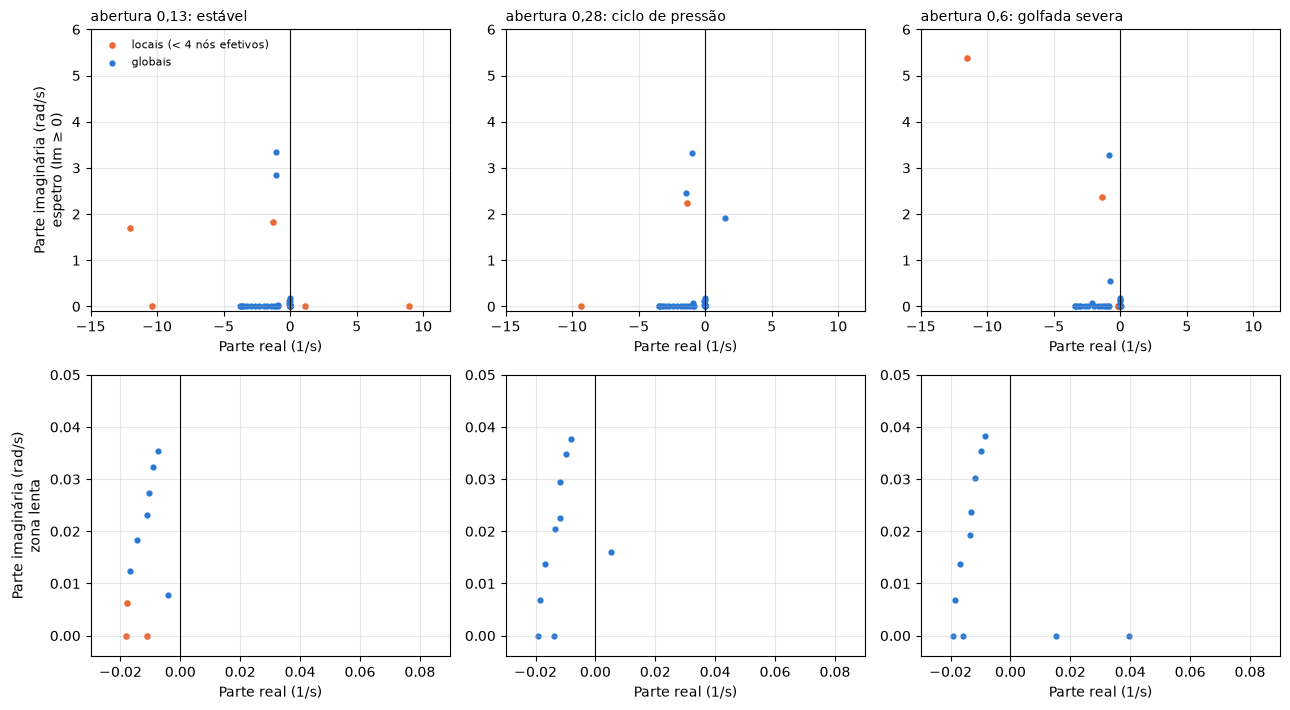

ponto                       resíduo  classe linear    1.º modo global lento  período           mais instável dos outros
0.13 (estável)                7e-13         stable    -0.00397+0.00778j    808 s       +8.96+0.00j (3.1 nós, nó 17)
0.28 (ciclo de pressão)       4e-10           hopf    +0.00522+0.01598j    393 s       +1.46+1.92j (5.0 nós, nó 17)
0.6 (golfada severa)          7e-10           real    +0.03954+0.00000j       --       -0.14+0.00j (3.4 nós, nó 19)


In [10]:
from mfsim.analysis import mode_participation, slow_global_modes


def steady_modes(ab):
    """Modos do estacionário de partida do ponto (15 bar, ab), sem a perturbação de partida."""
    r = run_of("steady", ab, P_SEL)
    m = r.model
    X = np.array(r.X[:, 0], float)
    X[m.state_slots() == 1] /= 1.0 + meta["perturb"]
    w, n_eff, node = mode_participation(m, X)
    return dict(
        w=w, n_eff=n_eff, node=node, res=float(np.linalg.norm(m.rhs(0.0, X))), modes=slow_global_modes(w, n_eff, node)
    )


spec = {ab: steady_modes(ab) for ab, _ in sel}
fig, axes = plt.subplots(2, 3, figsize=(13, 7.2))
for j, (ab, lab) in enumerate(sel):
    d = spec[ab]
    w, glob = d["w"], d["n_eff"] >= 4.0
    for k, (xl, yl) in enumerate((((-15, 12), (-0.1, 6.0)), ((-0.03, 0.09), (-0.004, 0.05)))):
        ax = axes[k, j]
        ax.scatter(w.real[~glob], w.imag[~glob], s=14, color=SERIES["blocked"], label="locais (< 4 nós efetivos)")
        ax.scatter(w.real[glob], w.imag[glob], s=12, color=SERIES["steady"], label="globais")
        ax.axvline(0, color=INK, lw=0.8)
        ax.set_xlim(*xl)
        ax.set_ylim(*yl)
        ax.grid(alpha=0.3)
        ax.set_xlabel("Parte real (1/s)")
    axes[0, j].set_title(f"abertura {ab:g}: {lab}".replace(".", ","), loc="left", fontsize=10)
axes[0, 0].set_ylabel("Parte imaginária (rad/s)\nespetro (Im ≥ 0)")
axes[1, 0].set_ylabel("Parte imaginária (rad/s)\nzona lenta")
axes[0, 0].legend(frameon=False, fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

print(
    f"{'ponto':26s} {'resíduo':>8s} {'classe linear':>14s} {'1.º modo global lento':>24s} {'período':>8s} {'mais instável dos outros':>34s}"
)
for ab, lab in sel:
    d = spec[ab]
    md = d["modes"]
    per = f"{2 * np.pi / md['im1']:.0f} s" if abs(md["im1"]) > 1e-9 else "--"
    oth = f"{md['re_other']:+.2f}{md['im_other']:+.2f}j ({md['n_eff_other']:.1f} nós, nó {md['node_other']})"
    print(
        f"{f'{ab:g} ({lab})':26s} {d['res']:8.0e} {md['cls']:>14s} {md['re1']:+11.5f}{md['im1']:+.5f}j {per:>8s} {oth:>34s}"
    )

### O cruzamento com a abertura a 15 bar

Parte real e período do modo global lento dominante do estacionário de cada abertura, por cima das classes da
simulação dinâmica. O par complexo atravessa o eixo onde o ciclo de pressão começa; mais aberto, o modo dominante
passa a real, e é aí que começa a golfada severa.

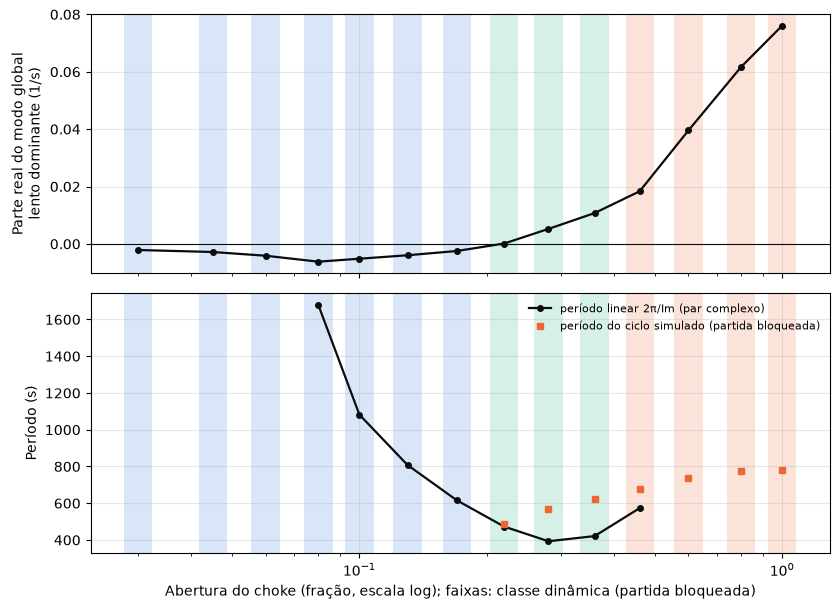

o modo global lento passa a instável entre as aberturas 0.17 e 0.22
abertura 0.030: λ1 -0.00213 /s (  real), linear stable | dinâmica: estacionário stable   bloqueada stable
abertura 0.045: λ1 -0.00283 /s (  real), linear stable | dinâmica: estacionário stable   bloqueada stable
abertura 0.060: λ1 -0.00413 /s (  real), linear stable | dinâmica: estacionário stable   bloqueada stable
abertura 0.080: λ1 -0.00620 /s (1678 s), linear stable | dinâmica: estacionário stable   bloqueada stable
abertura 0.100: λ1 -0.00517 /s (1082 s), linear stable | dinâmica: estacionário stable   bloqueada stable
abertura 0.130: λ1 -0.00397 /s ( 808 s), linear stable | dinâmica: estacionário stable   bloqueada stable
abertura 0.170: λ1 -0.00248 /s ( 616 s), linear stable | dinâmica: estacionário stable   bloqueada stable
abertura 0.220: λ1 +0.00013 /s ( 473 s), linear hopf   | dinâmica: estacionário stable   bloqueada cycling
abertura 0.280: λ1 +0.00522 /s ( 393 s), linear hopf   | dinâmica: estacionário cyc

In [11]:
line = sorted([G[("steady", P_SEL, ab)] for ab in openings], key=lambda r: r["ab"])
ab_l = np.array([r["ab"] for r in line])
re1 = np.array([r["lin_re1"] for r in line])
im1 = np.array([r["lin_im1"] for r in line])
fig, (a1, a2) = plt.subplots(2, 1, figsize=(8.5, 6.2), sharex=True)
for r in line:
    for a in (a1, a2):
        a.axvspan(
            r["ab"] / 1.08, r["ab"] * 1.08, color=CYCLE_COLORS[G[("blocked", P_SEL, r["ab"])]["cls"]], alpha=0.18, lw=0
        )
a1.axhline(0, color=INK, lw=0.8)
a1.plot(ab_l, re1, color=INK, lw=1.6, marker="o", ms=4)
a1.set_ylabel("Parte real do modo global\nlento dominante (1/s)")
cplx = np.abs(im1) > 1e-9
a2.plot(
    ab_l[cplx],
    2 * np.pi / np.abs(im1[cplx]),
    color=INK,
    lw=1.6,
    marker="o",
    ms=4,
    label="período linear 2π/Im (par complexo)",
)
cyc = [
    (r["ab"], G[("blocked", P_SEL, r["ab"])]["period"])
    for r in line
    if G[("blocked", P_SEL, r["ab"])]["cls"] != "stable"
]
a2.plot(
    [c[0] for c in cyc],
    [c[1] for c in cyc],
    color=SERIES["blocked"],
    lw=0,
    marker="s",
    ms=5,
    label="período do ciclo simulado (partida bloqueada)",
)
a2.set_ylabel("Período (s)")
a2.set_xlabel("Abertura do choke (fração, escala log); faixas: classe dinâmica (partida bloqueada)")
for a in (a1, a2):
    a.set_xscale("log")
    a.grid(alpha=0.3)
a2.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()
cross = [(line[i]["ab"], line[i + 1]["ab"]) for i in range(len(line) - 1) if re1[i] <= 0 < re1[i + 1]]
print("o modo global lento passa a instável entre as aberturas", ", ".join(f"{a:g} e {b:g}" for a, b in cross))
for r in line:
    per = f"{2 * np.pi / abs(r['lin_im1']):.0f} s" if abs(r["lin_im1"]) > 1e-9 else "real"
    print(
        f"abertura {r['ab']:5.3f}: λ1 {r['lin_re1']:+.5f} /s ({per:>6s}), linear {r['lin_cls']:6s} | dinâmica: estacionário {r['cls']:8s} bloqueada {G[('blocked', P_SEL, r['ab'])]['cls']}"
    )

### O mapa linear contra o mapa dinâmico

A classe linear de cada ponto (do seu estacionário, sem simular) e a sua concordância com as classes da
simulação dinâmica. Em cada célula do mapa linear, o período do par instável (Hopf) ou o tempo de crescimento
1/λ do modo real.

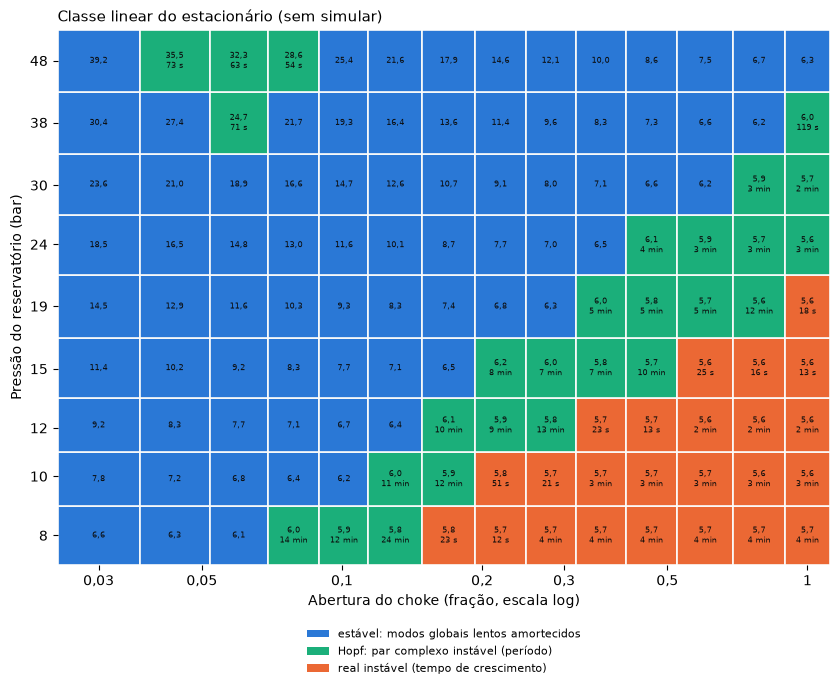


classe linear × classe dinâmica (partida do estacionário):
                    stable   cycling  slugging
stable                  75         0         0
hopf                     6        19         2
real                     0         1        23
concordância: 117 de 126

classe linear × classe dinâmica (partida bloqueada):
                    stable   cycling  slugging
stable                  73         2         0
hopf                     4        21         2
real                     0         1        23
concordância: 117 de 126

queda no choke (lei monofásica do líquido, produção do estacionário, CV 15) no cruzamento do par lento:
 P (bar)  abertura crítica  Δp crítico (bar)  abertura de Jansen
      10             0.104              0.37               0.068
      12             0.144              0.44               0.110
      15             0.217              0.45               0.172
      19             0.305              0.48               0.254
      24             0.457    

In [12]:
LIN = {"stable": "stable", "hopf": "cycling", "real": "slugging"}
lin_rows = []
for r in rows:
    if r["start"] != "steady":
        continue
    q = dict(r)
    q["cls"] = LIN.get(r["lin_cls"], "stable")
    q["period"] = (
        2 * np.pi / abs(r["lin_im1"])
        if r["lin_cls"] == "hopf"
        else (1 / r["lin_re1"] if r["lin_cls"] == "real" else np.nan)
    )
    q["P_max"] = q["P_mean"] = r["P_ss"]
    lin_rows.append(q)
fig, ax = plt.subplots(figsize=(8.5, 7.0))
xe, ye = cycle_map(ax, lin_rows, best=None)
ticks = [t for t in (0.03, 0.05, 0.1, 0.2, 0.3, 0.5, 1.0) if xe[0] <= t <= xe[-1]]
ax.set_xticks(ticks)
ax.set_xticklabels([f"{t:g}".replace(".", ",") for t in ticks])
ax.set_xlim(xe[0], xe[-1])
ax.set_xlabel("Abertura do choke (fração, escala log)")
ax.set_ylabel("Pressão do reservatório (bar)")
ax.set_title("Classe linear do estacionário (sem simular)", loc="left", fontsize=11)
ax.legend(
    handles=[
        Patch(fc=CYCLE_COLORS["stable"], label="estável: modos globais lentos amortecidos"),
        Patch(fc=CYCLE_COLORS["cycling"], label="Hopf: par complexo instável (período)"),
        Patch(fc=CYCLE_COLORS["slugging"], label="real instável (tempo de crescimento)"),
    ],
    loc="upper center",
    bbox_to_anchor=(0.5, -0.1),
    ncol=1,
    frameon=False,
    fontsize=8,
)
plt.tight_layout()
plt.show()

classes = ("stable", "cycling", "slugging")
for start in ("steady", "blocked"):
    print(f"\nclasse linear × classe dinâmica ({START_LABEL[start]}):")
    print(f"{'':16s} " + " ".join(f"{c:>9s}" for c in classes))
    hits = 0
    for lc in ("stable", "hopf", "real"):
        cnt = [sum(1 for r in rows if r["start"] == start and r["lin_cls"] == lc and r["cls"] == c) for c in classes]
        hits += cnt[classes.index(LIN[lc])]
        print(f"{lc:16s} " + " ".join(f"{n:9d}" for n in cnt))
    print(f"concordância: {hits} de {len(openings) * len(pressures)}")

print("\nqueda no choke (lei monofásica do líquido, produção do estacionário, CV 15) no cruzamento do par lento:")
print(f"{'P (bar)':>8s} {'abertura crítica':>17s} {'Δp crítico (bar)':>17s} {'abertura de Jansen':>19s}")
for P in pressures:
    ln = sorted([G[("steady", P, ab)] for ab in openings], key=lambda r: r["ab"])
    a_, re_, q_ = (np.array([r[k] for r in ln]) for k in ("ab", "lin_re1", "q_ss"))
    k = [
        i for i in range(len(ln) - 1) if re_[i] <= 0 < re_[i + 1] and a_[i] > 0.08
    ]  # sem as ilhas de choke muito fechado
    if not k:
        continue
    i = k[0]
    f = -re_[i] / (re_[i + 1] - re_[i])
    aH = float(np.exp(np.log(a_[i]) + f * np.log(a_[i + 1] / a_[i])))
    dpH = (q_[i] + f * (q_[i + 1] - q_[i])) ** 2 / 900.0 / (0.0075 * 15.0 * aH) ** 2
    aJ = jansen_choke_opening(a_, q_, dpc, CV=15.0)
    print(f"{P:8.0f} {aH:17.3f} {dpH:17.2f} {aJ if aJ else float('nan'):19.3f}")

Resultado dos testes da issue 042, feitos antes da correção da matriz de massa (guiões em
`runs/maps/prototype/`): suavizar as transições de fechamento na curva não tirava os modos locais, e estes
cresciam com o refinamento da malha (a 4× a integração falhava aos 821 s). Com a matriz de massa os modos locais
ficam muito menores e só aparecem nas aberturas pequenas. No ponto estável a 15 bar e 0,13 deste mapa, com a
fração das faces média (o padrão) há dois modos locais reais no ponto baixo (+9,0 e +1,1 /s); com a fração da
célula doadora (issue 044) desaparecem e fica um modo rápido oscilatório fraco (+0,19 /s, período 1,7 s,
espalhado por 18 nós). O par global lento é amortecido nos dois casos.

## Lições

- **A lei de válvula é parte do modelo de estabilidade.** Com a densidade ponderada por massa o choke não
  estabiliza nada; com a densidade por volume aparece uma fronteira com a forma do critério de Jansen (queda
  constante no choke), mas com um limiar mais baixo: ~0,4 bar no próprio modelo contra 0,67 bar do critério, e
  aberturas críticas 1,2 a 1,5 vezes as de Jansen. A fronteira dinâmica só parecia seguir Jansen pela resolução da
  grelha.
- **A estabilidade do estacionário vem do espetro, não de uma corrida.** A partida bloqueada dá o atrator de um
  poço que arranca de uma paragem; a classe linear diz se o equilíbrio é estável; a histerese real é o equilíbrio
  estável com a partida bloqueada a ciclar (aqui a 8 bar e 0,06 e a 30 bar e 0,6). A partida do estacionário perturbado não vê
  instabilidades lentas.
- **O tempo de cada corrida deve ser o que ela precisa, mas a paragem adaptativa não é um teste de estabilidade.**
  Os estáveis param aos 2000 s e os lentos seguem até aos 8000 s; um crescimento abaixo de ~10⁻³ /s passa
  despercebido.
- **A linearização de um modelo conservativo leva a matriz de massa.** Os autovalores de J sozinha davam modos
  rápidos espúrios e escondiam a bifurcação; com M, o estacionário prevê o mapa: Hopf onde o ciclo de pressão
  começa, modo real onde começa a golfada severa.
- **Uma partida no equilíbrio pede passo máximo.** Sem ele o BDF dá passos de centenas de segundos, amortece a
  instabilidade e a trajetória fica presa ao equilíbrio (issue 047).